# Trabajo 3 · Transfer learning, fine-tuning e interpretabilidad aplicados al TFM

**TFM Tema 50:** Integración y consolidación territorial de datos abiertos gubernamentales del Ecuador para la toma de decisiones
**Grupo:** Wilson Paredes, Diana Tandalla, Alexander Luna, Bryan Sarmiento

**Tarea.** Clasificación binaria tabular: predecir si una combinación **cantón-año** es una anomalía territorial, es decir, si la marcan al menos 2 de los 3 detectores no supervisados del TFM (Isolation Forest, LOF y One-Class SVM). Es el *modelo sustituto* de la entrega anterior: permite puntuar un cantón-año nuevo sin reajustar el ensamble y explicar qué indicador pesa en cada caso.

**Comparación.**
1. **Desde cero (entrega anterior):** MLP de dos capas ocultas (16 y 8 neuronas), con sobremuestreo de la clase minoritaria.
2. **Transfer learning:** TabPFN v1 (Hollmann et al., 2023), un transformer pre-entrenado sobre millones de tablas sintéticas, usado con sus pesos congelados (aprendizaje en contexto).
3. **Fine-tuning:** el mismo TabPFN, con sus dos últimas capas y su decodificador reentrenados sobre los datos del TFM.

**Explicabilidad:** SHAP (Kernel SHAP) sobre el modelo ajustado.

In [13]:
# 0. Entorno. En Colab: descomentar la instalación.
!pip install -q shap
!pip install -q --no-deps tabpfn==0.1.10        # código de TabPFN v1 (los pesos se descargan abajo)
import os, sys, json, time, copy, warnings, pathlib
import numpy as np, pandas as pd, torch, sklearn, shap
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score
warnings.filterwarnings("ignore")
torch.set_num_threads(max(1, os.cpu_count() or 1))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
SEMILLA, N_REP, FRAC_TEST, CONTAM = 42, 10, 0.20, 0.05
print("python", sys.version.split()[0], "| torch", torch.__version__, "| scikit-learn", sklearn.__version__, "| shap", shap.__version__)

python 3.13.15 | torch 2.11.0+cu130 | scikit-learn 1.6.1 | shap 0.54.1


In [14]:
import pathlib
import urllib.request
import torch
import sys

# 1. Pesos pre-entrenados de TabPFN v1 (103 MB). El enlace de la librería apunta a la rama main, que ya no los tiene;
#    se descargan de la etiqueta v1.0.0 del repositorio oficial (automl/TabPFN).
BASE = pathlib.Path("tabpfn_base"); CKPT = BASE / "models_diff" / "prior_diff_real_checkpoint_n_0_epoch_42.cpkt"
if not CKPT.exists():
    CKPT.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve("https://github.com/automl/TabPFN/raw/v1.0.0/tabpfn/models_diff/prior_diff_real_checkpoint_n_0_epoch_42.cpkt", CKPT)
print("checkpoint:", CKPT, round(CKPT.stat().st_size / 1e6, 1), "MB")

# Deshacer posibles parches recursivos previos recargando módulos limpios si es necesario
if hasattr(torch, "__original_load"):
    torch.load = torch.__original_load
else:
    torch.__original_load = torch.load

torch.load = lambda *a, **k: torch.__original_load(*a, **{**k, "weights_only": False})

import typing, torch.nn as _nn, torch.nn.modules.transformer as _tt
for _n, _v in dict(Optional=typing.Optional, Tensor=torch.Tensor, Module=_nn.Module, MultiheadAttention=_nn.MultiheadAttention,
                   Linear=_nn.Linear, Dropout=_nn.Dropout, LayerNorm=_nn.LayerNorm).items():
    if not hasattr(_tt, _n): setattr(_tt, _n, _v)

import tabpfn.scripts.transformer_prediction_interface as tpi
if not hasattr(tpi, "__original_lmw"):
    tpi.__original_lmw = tpi.load_model_workflow

tpi.load_model_workflow = lambda i, e, **k: tpi.__original_lmw(i, 42, **k)

from sklearn.utils.validation import check_X_y as _cxy, check_array as _ca
tpi.check_X_y = lambda X, y, **k: _cxy(X, y)                                  # 'force_all_finite' ya no existe en sklearn 1.8+
tpi.check_array = lambda X, **k: _ca(X)

from tabpfn import TabPFNClassifier

checkpoint: tabpfn_base/models_diff/prior_diff_real_checkpoint_n_0_epoch_42.cpkt 103.4 MB


## 1. Datos del TFM
Matriz efectiva del capítulo 4: **807 combinaciones cantón-año** (ventana 2021–2025, 218 cantones) × **10 indicadores de 8 instituciones**. Cada valor es el logaritmo del cociente de localización: la tasa por mil habitantes del cantón (Censo 2022) dividida por la tasa nacional del mismo año. Las celdas sin dato se imputan con la mediana de los demás años del mismo cantón, ajustada solo con la partición de entrenamiento.

In [15]:
D = pd.read_csv("https://raw.githubusercontent.com/Alexander-Luna/NeuralNetworks-DeepLearning/97c76f4c322643785a2dd18e62c430451a727561/SEMANA%203/matriz_trabajo3.csv", dtype={"cod_canton": str, "cod_provincia": str})
IND = list(D.columns[5:])
NOMBRE_CORTO = {"Permisos de funcionamiento": "Permisos funcionamiento (ACESS)", "Patrimonio cultural inmaterial": "Patrimonio inmaterial (INPC)",
                "RUAC artistas y gestores": "Artistas y gestores (MCYP)", "Inspección de control posterior": "Inspecciones control (MPCEIP)",
                "Movilidad humana: vulnerabilidades": "Movilidad humana (MREMH)", "Superficie bajo conservación": "Superficie conservación (MAATE)",
                "Volumen forestal unidades móviles": "Volumen forestal (MAATE)", "Atención ciudadana": "Atención ciudadana (Presidencia)",
                "Gestantes en programas MIES": "Gestantes en programas (STECSDI)", "Menores de 24 meses con alerta": "Menores 24 m con alerta (STECSDI)"}
CORTO = [NOMBRE_CORTO[c.split(" · ")[1]] for c in IND]
Xraw = D[IND].values.astype(float); canton = D.cod_canton.values; prov = D.cod_provincia.values
print(f"{len(D)} filas, {D.cod_canton.nunique()} cantones, {D.cod_provincia.nunique()} provincias, {len(IND)} indicadores")
print(f"celdas con dato: {np.isfinite(Xraw).mean():.1%}")
D[IND].describe().T.round(2)[["count", "mean", "std", "min", "max"]]

807 filas, 218 cantones, 24 provincias, 10 indicadores
celdas con dato: 62.0%


,count,mean,std,min,max
ACESS · Permisos de funcionamiento,625.0,-0.41,0.68,-3.38,1.37
INPC · Patrimonio cultural inmaterial,736.0,0.10,1.67,-4.29,3.65
MCYP · RUAC artistas y gestores,768.0,-1.11,1.14,-4.21,1.66
MPCEIP · Inspección de control posterior,301.0,-0.92,1.31,-6.39,1.61
MREMH · Movilidad humana: vulnerabilidades,381.0,-0.39,1.14,-3.47,2.65
MAATE · Superficie bajo conservación,163.0,0.20,1.46,-4.52,3.29
MAATE · Volumen forestal unidades móviles,493.0,-0.70,1.54,-4.71,3.32
PRESIDENCIA · Atención ciudadana,674.0,-1.08,0.94,-3.41,2.14
STECSDI · Gestantes en programas MIES,429.0,0.13,0.57,-2.64,1.83
STECSDI · Menores de 24 meses con alerta,430.0,0.09,0.40,-1.19,1.55


In [16]:
# 2. Etiqueta sin fuga de información (igual que en la entrega anterior): los detectores se ajustan SOLO con entrenamiento
#    y la etiqueta de prueba se obtiene aplicándoles las filas de prueba.
class ImputadorHistoria:
    """Mediana de los demás años del mismo cantón; si no hay, media de la columna (ajustada en entrenamiento)."""
    def fit(self, X): self.media_ = np.nanmean(X, axis=0); return self
    def transform(self, X, grupos):
        med = pd.DataFrame(X).groupby(np.asarray(grupos)).transform("median").values
        return np.where(np.isnan(X), np.where(np.isnan(med), self.media_, med), X)

def detectores(Xtr, semilla):
    iso = IsolationForest(n_estimators=300, contamination=CONTAM, random_state=semilla).fit(Xtr)
    lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAM); v = (iso.predict(Xtr) == -1).astype(int) + (lof.fit_predict(Xtr) == -1)
    lof_nv = LocalOutlierFactor(n_neighbors=20, contamination=CONTAM, novelty=True).fit(Xtr)
    sc = StandardScaler().fit(Xtr); svm = OneClassSVM(kernel="rbf", nu=CONTAM, gamma="scale").fit(sc.transform(Xtr))
    v = v + (svm.predict(sc.transform(Xtr)) == -1)
    votos_te = lambda X: (iso.predict(X) == -1).astype(int) + (lof_nv.predict(X) == -1) + (svm.predict(sc.transform(X)) == -1)
    return v, votos_te

def division(esquema, semilla):
    idx = np.arange(len(Xraw))
    if esquema == "Filas al azar": return next(ShuffleSplit(1, test_size=FRAC_TEST, random_state=semilla).split(idx))
    g = canton if esquema == "Cantones nuevos" else prov
    return next(GroupShuffleSplit(1, test_size=FRAC_TEST, random_state=semilla).split(idx, groups=g))

def preparar(tr, te, semilla):
    imp = ImputadorHistoria().fit(Xraw[tr])
    Xtr, Xte = imp.transform(Xraw[tr], canton[tr]), imp.transform(Xraw[te], canton[te])
    v, f = detectores(Xtr, semilla)
    return Xtr, Xte, (v >= 2).astype(int), (f(Xte) >= 2).astype(int)

tr, te = division("Filas al azar", 0); Xtr, Xte, ytr, yte = preparar(tr, te, 0)
print(f"ejemplo: entrenamiento {len(ytr)} filas ({ytr.sum()} anomalías, {ytr.mean():.1%}); prueba {len(yte)} ({yte.sum()} anomalías)")

ejemplo: entrenamiento 645 filas (27 anomalías, 4.2%); prueba 162 (8 anomalías)


## 2. Modelo entrenado desde cero (entrega anterior)
MLP de scikit-learn con dos capas ocultas (16 y 8, ReLU), Adam, 150 épocas, entradas estandarizadas y **sobremuestreo** de la clase minoritaria, porque las anomalías son ~5 % de las filas. Se mantiene igual que en la entrega anterior para que la comparación sea justa; también se reporta una regresión logística como referencia lineal.

In [17]:
def mlp_desde_cero(Xtr, ytr, Xte, semilla):
    sc = StandardScaler().fit(Xtr); Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
    rg = np.random.RandomState(semilla); pos = np.where(ytr == 1)[0]; extra = rg.choice(pos, (ytr == 0).sum() - len(pos))
    m = MLPClassifier(hidden_layer_sizes=(16, 8), learning_rate_init=1e-3, batch_size=64, max_iter=150,
                      n_iter_no_change=150, random_state=semilla).fit(np.vstack([Ztr, Ztr[extra]]), np.r_[ytr, ytr[extra]])
    return m.predict_proba(Zte)[:, 1]

def logistica(Xtr, ytr, Xte, semilla):
    sc = StandardScaler().fit(Xtr)
    return LogisticRegression(class_weight="balanced", max_iter=1000).fit(sc.transform(Xtr), ytr).predict_proba(sc.transform(Xte))[:, 1]

## 3. Modelo pre-entrenado: TabPFN v1
**Por qué.** La tarea es tabular, pequeña (≈650 filas de entrenamiento, 10 variables numéricas) y desbalanceada. Los modelos de Keras Applications o KerasNLP son para imágenes o texto; para tablas pequeñas, el modelo pre-entrenado de referencia es **TabPFN** (*Prior-Data Fitted Network*), que admite hasta 1.024 filas de entrenamiento, 100 variables y 10 clases: el caso del TFM está dentro de esos límites.

**Arquitectura y datos de origen.** Transformer de 12 capas (embedding 512, 4 cabezas, MLP interna de 1.024) con un codificador lineal de variables (hasta 100), un codificador de la etiqueta y un decodificador MLP a 10 clases. Se pre-entrenó con **millones de tablas sintéticas** generadas por un *prior* de redes causales estructurales y redes bayesianas aleatorias: aprendió a hacer inferencia bayesiana aproximada para clasificación tabular. En predicción, recibe el conjunto de entrenamiento como contexto y clasifica las filas nuevas en un solo paso hacia adelante.

In [18]:
import sys
import importlib
import torch
import tabpfn.scripts.transformer_prediction_interface as tpi
import tabpfn.scripts.model_builder as mb

# 1. Limpieza y restauración segura de los módulos de tabpfn sin recargar torch
importlib.reload(tpi)
importlib.reload(mb)

# 2. Restaurar referencias originales para eliminar recursiones antiguas en torch si existen
if hasattr(torch, "__original_load"):
    torch.load = torch.__original_load
else:
    # Si no tiene el atributo pero es una lambda recursiva, intentamos des-referenciarla recursivamente
    while hasattr(torch.load, "__code__") and torch.load.__code__.co_name == "<lambda>":
        # Buscamos en el closure si guardó la función original
        if torch.load.__closure__:
            for cell in torch.load.__closure__:
                if callable(cell.cell_contents) and cell.cell_contents.__name__ == "load":
                    torch.load = cell.cell_contents
                    break
            else:
                break
        else:
            break

# Asegurar que guardamos el original limpio y aplicamos el parche sin ciclos infinitos
torch.__original_load = torch.load
torch.load = lambda *a, **k: torch.__original_load(*a, **{**k, "weights_only": False})

if not hasattr(tpi, "__original_lmw"):
    tpi.__original_lmw = tpi.load_model_workflow
tpi.load_model_workflow = lambda i, e, **k: tpi.__original_lmw(i, 42, **k)

from sklearn.utils.validation import check_X_y as _cxy, check_array as _ca
tpi.check_X_y = lambda X, y, **k: _cxy(X, y)
tpi.check_array = lambda X, **k: _ca(X)

# 3. Inicializar el clasificador con la configuración limpia
from tabpfn import TabPFNClassifier
clf0 = TabPFNClassifier(device="cpu", base_path=BASE, N_ensemble_configurations=8, seed=SEMILLA)

modelo = clf0.model[2]; cfg = clf0.c
n_par = sum(p.numel() for p in modelo.parameters())
print(f"TabPFN v1: {cfg['nlayers']} capas, emsize={cfg['emsize']}, cabezas={cfg['nhead']}, variables máx.={cfg['num_features']}, clases máx.={cfg['max_num_classes']}")
print(f"parámetros: {n_par/1e6:.2f} M")
print(modelo.encoder, modelo.decoder, sep="\n")

TabPFN v1: 12 capas, emsize=512, cabezas=4, variables máx.=100, clases máx.=10
parámetros: 25.82 M
Linear(in_features=100, out_features=512, bias=True)
Sequential(
  (0): Linear(in_features=512, out_features=1024, bias=True)
  (1): GELU(approximate='none')
  (2): Linear(in_features=1024, out_features=10, bias=True)
)


### 3.1 Preparación de los datos para TabPFN
- **Sin valores faltantes:** se aplica la misma imputación por historia del cantón (TabPFN v1 no fue pre-entrenado con muchos faltantes).
- **Normalización:** TabPFN espera variables centradas y escaladas; el propio modelo aplica normalización con estadísticos del contexto, recorte de atípicos a ±4 desviaciones y escalado por número de variables usadas (`normalize_by_used_features`), y **rellena con ceros hasta 100 variables**, el tamaño de entrada del codificador pre-entrenado.
- **Etiquetas:** 0/1 se codifican en las dos primeras de las 10 salidas del decodificador; las otras 8 se ignoran.
- **Contexto:** todo el entrenamiento (≈650 filas, por debajo del límite de 1.024).

In [19]:
from tabpfn.utils import normalize_data, normalize_by_used_features_f
def a_tensor(Xctx, Xq):
    """Replica el preprocesamiento de TabPFN v1 sin ensamble: z-score con el contexto, recorte, escalado y relleno a 100."""
    X = np.vstack([Xctx, Xq]).astype(np.float32)
    mu, sd = Xctx.mean(0), Xctx.std(0) + 1e-6
    X = np.clip((X - mu) / sd, -4, 4)
    t = torch.tensor(X).unsqueeze(1)                                   # (filas, lote=1, variables)
    t = normalize_by_used_features_f(t, X.shape[1], cfg["num_features"], normalize_with_sqrt=False)
    return torch.cat([t, torch.zeros(t.shape[0], 1, cfg["num_features"] - X.shape[1])], -1).float()

def logits_tabpfn(m, Xctx, yctx, Xq):
    x = a_tensor(Xctx, Xq); y = torch.tensor(np.r_[yctx, np.zeros(len(Xq))], dtype=torch.float32).unsqueeze(1)
    return m((None, x, y), single_eval_pos=len(Xctx))[:, 0, :2]       # solo las salidas de las clases 0 y 1

def tabpfn_transfer(Xtr, ytr, Xte, semilla):
    """Transfer learning sin actualizar pesos: aprendizaje en contexto con ensamble de 8 configuraciones (API oficial)."""
    c = TabPFNClassifier(device="cpu", base_path=BASE, N_ensemble_configurations=8, seed=semilla).fit(Xtr, ytr)
    return c.predict_proba(Xte)[:, 1]

### 3.2 Estrategia de fine-tuning
Se conserva la arquitectura y se **congelan el codificador y las 10 primeras capas** del transformer, que contienen el conocimiento general sobre tablas. Se **reentrenan las 2 últimas capas y el decodificador** (4,7 M de 25,8 M parámetros, 18 %) para que el modelo se especialice en la frontera del consenso del TFM. Cambios respecto del original: salida restringida a 2 clases y pérdida de entropía cruzada **ponderada por clase** (para el desbalance).

**Entrenamiento por episodios** (como en el pre-entrenamiento): en cada paso se divide el entrenamiento en un contexto (70 %) y una consulta (30 %, estratificada), y la pérdida se calcula sobre la consulta. Adam, tasa 1e-5, 60 pasos, recorte de gradiente a 1. La prueba nunca interviene.

parámetros entrenables: 4.74 M de 25.82 M (18%); tiempo: 65 s


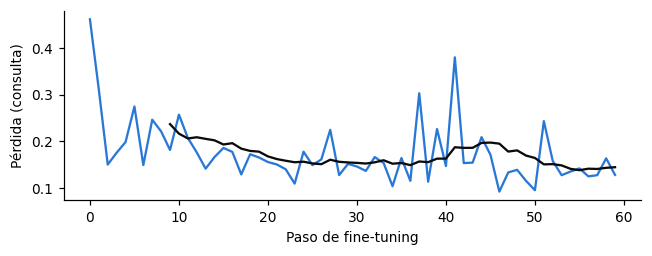

In [20]:
def fine_tune(Xtr, ytr, semilla, pasos=60, lr=1e-5, capas_libres=2, registrar=False):
    torch.manual_seed(semilla); rg = np.random.RandomState(semilla)
    m = copy.deepcopy(modelo); m.train()
    for p in m.parameters(): p.requires_grad = False
    for capa in m.transformer_encoder.layers[-capas_libres:]:
        for p in capa.parameters(): p.requires_grad = True
    for p in m.decoder.parameters(): p.requires_grad = True
    libres = [p for p in m.parameters() if p.requires_grad]
    opt = torch.optim.Adam(libres, lr=lr)
    w = torch.tensor([1.0, (ytr == 0).sum() / max(1, ytr.sum())], dtype=torch.float32) ** 0.5   # ponderación suave
    pos, neg = np.where(ytr == 1)[0], np.where(ytr == 0)[0]; hist = []
    for paso in range(pasos):
        q = np.r_[rg.choice(pos, max(1, int(0.3 * len(pos))), replace=False), rg.choice(neg, int(0.3 * len(neg)), replace=False)]
        ctx = np.setdiff1d(np.arange(len(ytr)), q)
        out = logits_tabpfn(m, Xtr[ctx], ytr[ctx], Xtr[q])
        loss = torch.nn.functional.cross_entropy(out, torch.tensor(ytr[q]), weight=w)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(libres, 1.0); opt.step(); hist.append(float(loss))
    m.eval()
    return (m, hist, sum(p.numel() for p in libres)) if registrar else m

def tabpfn_finetuned(Xtr, ytr, Xte, semilla):
    m = fine_tune(Xtr, ytr, semilla)
    with torch.no_grad(): return torch.softmax(logits_tabpfn(m, Xtr, ytr, Xte), -1)[:, 1].numpy()

def tabpfn_base_mismo_preproc(Xtr, ytr, Xte, semilla):
    """Control: el modelo pre-entrenado con el mismo preprocesamiento simple que el ajustado (aisla el efecto del fine-tuning)."""
    with torch.no_grad(): return torch.softmax(logits_tabpfn(modelo, Xtr, ytr, Xte), -1)[:, 1].numpy()

t0 = time.time(); m_ft, hist, n_libres = fine_tune(Xtr, ytr, 0, registrar=True)
print(f"parámetros entrenables: {n_libres/1e6:.2f} M de {n_par/1e6:.2f} M ({n_libres/n_par:.0%}); tiempo: {time.time()-t0:.0f} s")
fig, ax = plt.subplots(figsize=(6, 2.4)); ax.plot(hist, color="#2a78d6"); ax.plot(pd.Series(hist).rolling(10).mean(), color="#0b0b0b", lw=1.5)
ax.set_xlabel("Paso de fine-tuning"); ax.set_ylabel("Pérdida (consulta)"); plt.tight_layout(); plt.savefig("fig_t3_perdida.png", dpi=200); plt.show()

## 4. Evaluación y comparación
Mismo protocolo que la entrega anterior: **3 esquemas de división** (filas al azar; cantones nuevos, reservando el 20 % de los cantones con todos sus años; provincias nuevas) × **10 repeticiones**. Se descartan los folds con menos de 3 anomalías en prueba (con 1 positivo, la PR-AUC es 0 o 1). Métricas sobre la clase anomalía: precisión, *recall*, **F1** (umbral 0,5) y **PR-AUC** (independiente del umbral, adecuada con ~5 % de positivos).

In [21]:
MODELOS = {"MLP desde cero": mlp_desde_cero, "Regresión logística": logistica,
           "TabPFN transfer (pesos congelados)": tabpfn_transfer, "TabPFN mismo preproc. (control)": tabpfn_base_mismo_preproc,
           "TabPFN fine-tuning": tabpfn_finetuned}
filas = []; t_all = time.time()
for esquema in ("Filas al azar", "Cantones nuevos", "Provincias nuevas"):
    for s in range(N_REP):
        tr, te = division(esquema, s); Xtr, Xte, ytr, yte = preparar(tr, te, s)
        if ytr.sum() < 3 or yte.sum() < 3: continue            # con menos de 3 anomalías en prueba las métricas no son estables
        for nombre, f in MODELOS.items():
            t0 = time.time(); p = f(Xtr, ytr, Xte, s); yp = (p >= 0.5).astype(int)
            filas.append(dict(esquema=esquema, modelo=nombre, rep=s, pos_test=int(yte.sum()), segundos=time.time() - t0,
                              precision=precision_score(yte, yp, zero_division=0), recall=recall_score(yte, yp),
                              f1=f1_score(yte, yp, zero_division=0), pr_auc=average_precision_score(yte, p)))
R = pd.DataFrame(filas)
print(f"tiempo total: {(time.time()-t_all)/60:.1f} min, folds válidos por modelo: {R.groupby('modelo').size().iloc[0]}")
tabla = R.groupby(["esquema", "modelo"], sort=False)[["precision", "recall", "f1", "pr_auc", "segundos"]].agg(["mean", "std"]).round(3)
tabla

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimizatio

tiempo total: 22.9 min, folds válidos por modelo: 28


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


precision        recall  \
                                                          mean    std   mean   
esquema           modelo                                                       
Filas al azar     MLP desde cero                         0.358  0.185  0.356   
                  Regresión logística                    0.089  0.058  0.524   
                  TabPFN transfer (pesos congelados)     0.626  0.396  0.320   
                  TabPFN mismo preproc. (control)        0.648  0.444  0.292   
                  TabPFN fine-tuning                     0.551  0.260  0.643   
Cantones nuevos   MLP desde cero                         0.555  0.343  0.169   
                  Regresión logística                    0.179  0.063  0.489   
                  TabPFN transfer (pesos congelados)     0.889  0.333  0.355   
                  TabPFN mismo preproc. (control)        0.889  0.333  0.322   
                  TabPFN fine-tuning                     0.790  0.197  0.722   
Provincias nuevas MLP desde cero                         0.432  0.349  0.258   
                  Regresión logística                    0.129  0.053  0.504   
                  TabPFN transfer (pesos congelados)     0.707  0.355  0.263   
                  TabPFN mismo preproc. (control)        0.796  0.360  0.214   
                  TabPFN fine-tuning                     0.667  0.187  0.727   

                                                                f1         \
                                                        std   mean    std   
esquema           modelo                                                    
Filas al azar     MLP desde cero                      0.272  0.338  0.200   
                  Regresión logística                 0.326  0.150  0.095   
                  TabPFN transfer (pesos congelados)  0.222  0.417  0.275   
                  TabPFN mismo preproc. (control)     0.215  0.394  0.282   
                  TabPFN fine-tuning                  0.229  0.558  0.194   
Cantones nuevos   MLP desde cero                      0.113  0.253  0.157   
                  Regresión logística                 0.220  0.255  0.090   
                  TabPFN transfer (pesos congelados)  0.180  0.498  0.226   
                  TabPFN mismo preproc. (control)     0.185  0.458  0.233   
                  TabPFN fine-tuning                  0.208  0.747  0.185   
Provincias nuevas MLP desde cero                      0.278  0.267  0.214   
                  Regresión logística                 0.252  0.198  0.075   
                  TabPFN transfer (pesos congelados)  0.176  0.366  0.230   
                  TabPFN mismo preproc. (control)     0.177  0.310  0.222   
                  TabPFN fine-tuning                  0.192  0.664  0.104   

                                                     pr_auc        segundos  \
                                                       mean    std     mean   
esquema           modelo                                                      
Filas al azar     MLP desde cero                      0.362  0.217    1.195   
                  Regresión logística                 0.247  0.156    0.006   
                  TabPFN transfer (pesos congelados)  0.664  0.149    6.125   
                  TabPFN mismo preproc. (control)     0.630  0.164    0.633   
                  TabPFN fine-tuning                  0.703  0.192   42.152   
Cantones nuevos   MLP desde cero                      0.456  0.155    1.195   
                  Regresión logística                 0.257  0.115    0.006   
                  TabPFN transfer (pesos congelados)  0.806  0.191    6.126   
                  TabPFN mismo preproc. (control)     0.809  0.197    0.642   
                  TabPFN fine-tuning                  0.878  0.136   39.697   
Provincias nuevas MLP desde cero                      0.367  0.230    1.148   
                  Regresión logística                 0.205  0.105    0.006   
                  TabPFN transfer (pesos

In [22]:
# Diferencia pareada frente al MLP desde cero (mismos folds): media e intervalo de confianza del 95 % por bootstrap
def ic_bootstrap(d, n=5000, seed=0):
    rg = np.random.RandomState(seed); b = [rg.choice(d, len(d)).mean() for _ in range(n)]; return np.mean(d), np.percentile(b, 2.5), np.percentile(b, 97.5)
piv = R.pivot_table(index=["esquema", "rep"], columns="modelo", values=["f1", "pr_auc"])
comp = []
for esquema in R.esquema.unique():
    for met in ("f1", "pr_auc"):
        for mod in ("TabPFN transfer (pesos congelados)", "TabPFN fine-tuning"):
            d = (piv.loc[esquema][(met, mod)] - piv.loc[esquema][(met, "MLP desde cero")]).dropna().values
            m_, lo, hi = ic_bootstrap(d); comp.append(dict(esquema=esquema, metrica=met, modelo=mod, dif_vs_MLP=round(m_, 3), ic95=f"[{lo:.3f}, {hi:.3f}]"))
C = pd.DataFrame(comp); C

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,esquema,metrica,modelo,dif_vs_MLP,ic95
0,Filas al azar,f1,TabPFN transfer (pesos congelados),0.080,"[-0.034, 0.184]"
1,Filas al azar,f1,TabPFN fine-tuning,0.221,"[0.070, 0.370]"
2,Filas al azar,pr_auc,TabPFN transfer (pesos congelados),0.302,"[0.176, 0.428]"
3,Filas al azar,pr_auc,TabPFN fine-tuning,0.341,"[0.200, 0.485]"
4,Cantones nuevos,f1,TabPFN transfer (pesos congelados),0.246,"[0.124, 0.374]"
5,Cantones nuevos,f1,TabPFN fine-tuning,0.494,"[0.414, 0.571]"
6,Cantones nuevos,pr_auc,TabPFN transfer (pesos congelados),0.350,"[0.305, 0.392]"
7,Cantones nuevos,pr_auc,TabPFN fine-tuning,0.423,"[0.370, 0.471]"
8,Provincias nuevas,f1,TabPFN transfer (pesos congelados),0.099,"[0.027, 0.182]"
9,Provincias nuevas,f1,TabPFN fine-tuning,0.397,"[0.276, 0.515]"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


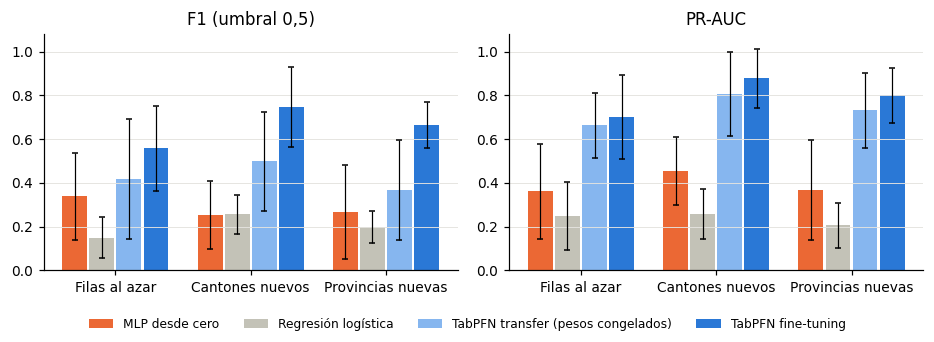

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
orden = ["MLP desde cero", "Regresión logística", "TabPFN transfer (pesos congelados)", "TabPFN fine-tuning"]
colores = ["#eb6834", "#c3c2b7", "#86b6ef", "#2a78d6"]
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.1), sharey=False)
for ax, met, tit in zip(axes, ("f1", "pr_auc"), ("F1 (umbral 0,5)", "PR-AUC")):
    g = R[R.modelo.isin(orden)].groupby(["esquema", "modelo"], sort=False)[met].agg(["mean", "std"]).reset_index()
    esq = list(R.esquema.unique()); w = 0.2
    for k, mod in enumerate(orden):
        gg = g[g.modelo == mod].set_index("esquema").loc[esq]
        ax.bar(np.arange(3) + (k - 1.5) * w, gg["mean"], w * 0.92, yerr=gg["std"], capsize=2, color=colores[k], label=mod, error_kw=dict(lw=0.8))
    ax.set_xticks(range(3), esq); ax.set_title(tit); ax.set_ylim(0, 1); ax.grid(axis="y", color="#e4e3df", lw=0.6)
for ax in axes: ax.set_ylim(0, 1.08)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=8, loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.savefig("fig_t3_comparacion.png", dpi=200); plt.show()

## 5. Explicabilidad con SHAP
**Por qué SHAP.** TabPFN es un transformer que no expone importancias propias, y Grad-CAM es para imágenes. SHAP (valores de Shapley) es agnóstico al modelo, tiene base teórica en teoría de juegos y da una contribución por indicador **para cada cantón-año**, que es lo que necesita la revisión experta del TFM. Se usa **Kernel SHAP** con 20 filas de fondo (k-medias del entrenamiento) sobre el modelo con fine-tuning, en la división por cantones nuevos. Se explican la probabilidad de anomalía de todas las anomalías de prueba y de una muestra de filas normales.

SHAP: 54 filas en 257 s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


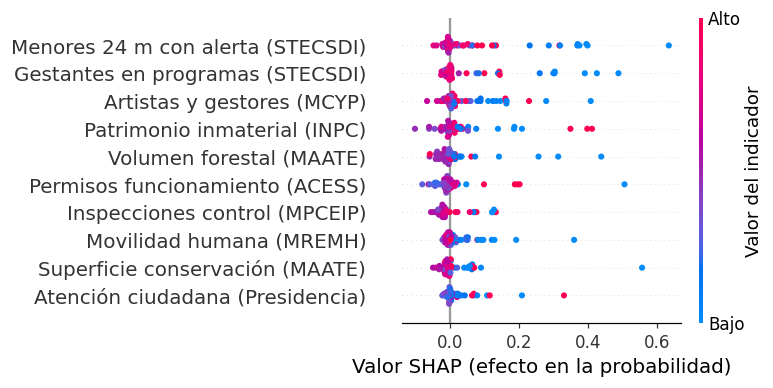

In [24]:
tr, te = division("Cantones nuevos", 0); Xtr, Xte, ytr, yte = preparar(tr, te, 0)
m_shap = fine_tune(Xtr, ytr, 0)
def f_prob(Xq):
    with torch.no_grad(): return torch.softmax(logits_tabpfn(m_shap, Xtr, ytr, np.asarray(Xq)), -1)[:, 1].numpy()
rg = np.random.RandomState(0); sel = np.r_[np.where(yte == 1)[0], rg.choice(np.where(yte == 0)[0], 30, replace=False)]
fondo = shap.kmeans(Xtr, 20)
expl = shap.KernelExplainer(f_prob, fondo)
t0 = time.time(); sv = expl.shap_values(Xte[sel], nsamples=300, silent=True); print(f"SHAP: {len(sel)} filas en {time.time()-t0:.0f} s")
E = shap.Explanation(values=sv, base_values=np.full(len(sel), expl.expected_value), data=Xte[sel], feature_names=CORTO)
def a_espanol(fig, xlabel):
    fig.axes[0].set_xlabel(xlabel)
    if len(fig.axes) > 1:                                             # barra de color del beeswarm
        cb = fig.axes[-1]; cb.set_ylabel("Valor del indicador"); cb.set_yticklabels(["Bajo", "Alto"])
shap.plots.beeswarm(E, max_display=10, show=False); fig = plt.gcf(); fig.set_size_inches(7, 3.6)
a_espanol(fig, "Valor SHAP (efecto en la probabilidad)"); plt.tight_layout(); plt.savefig("fig_t3_shap_beeswarm.png", dpi=200); plt.show()

,media |SHAP|
STECSDI · Menores de 24 meses con alerta,0.0919
STECSDI · Gestantes en programas MIES,0.0680
MCYP · RUAC artistas y gestores,0.0551
INPC · Patrimonio cultural inmaterial,0.0538
MAATE · Volumen forestal unidades móviles,0.0389
ACESS · Permisos de funcionamiento,0.0381
MPCEIP · Inspección de control posterior,0.0355
MREMH · Movilidad humana: vulnerabilidades,0.0325
MAATE · Superficie bajo conservación,0.0322
PRESIDENCIA · Atención ciudadana,0.0278


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


anomalías explicadas: 24; el indicador de mayor |SHAP| coincide con el de mayor |z| en 71% de los casos
caso: RUMIÑAHUI (PICHINCHA) 2022
indicadores imputados en el caso: ['Permisos funcionamiento (ACESS)', 'Movilidad humana (MREMH)', 'Gestantes en programas (STECSDI)', 'Menores 24 m con alerta (STECSDI)']
anomalías cuya mayor contribución SHAP viene de un valor imputado: 25%


/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'o

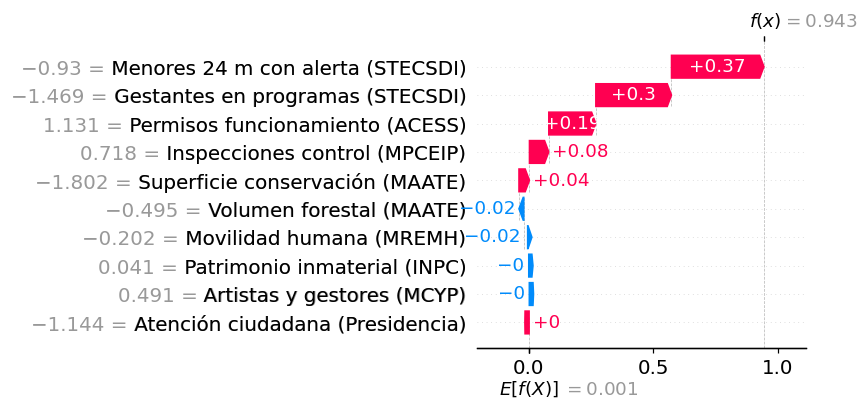

In [25]:
# Importancia global (media |SHAP|) y coherencia con el motivo del TFM:
# ¿el indicador con mayor |SHAP| coincide con el indicador más desviado (máx |z|) que usa el capítulo 4 para explicar cada caso?
imp_glob = pd.Series(np.abs(sv).mean(0), index=IND).sort_values(ascending=False)
display(imp_glob.round(4).to_frame("media |SHAP|"))
Z = (Xte - Xtr.mean(0)) / Xtr.std(0)
anom = np.where(yte[sel] == 1)[0]
coincide = np.mean([np.abs(sv[i]).argmax() == np.abs(Z[sel][i]).argmax() for i in anom])
print(f"anomalías explicadas: {len(anom)}; el indicador de mayor |SHAP| coincide con el de mayor |z| en {coincide:.0%} de los casos")
# Caso individual: la anomalía con mayor probabilidad
i0 = anom[np.argmax(f_prob(Xte[sel][anom]))]; fila = D.iloc[te[sel[i0]]]
print(f"caso: {fila.canton} ({fila.provincia}) {fila.anio}")
falt = np.isnan(Xraw[te[sel]])                                          # True = valor imputado (no publicado ese año)
print("indicadores imputados en el caso:", [CORTO[j] for j in np.where(falt[i0])[0]])
dom_imp = np.mean([falt[i, np.abs(sv[i]).argmax()] for i in anom])
print(f"anomalías cuya mayor contribución SHAP viene de un valor imputado: {dom_imp:.0%}")
shap.plots.waterfall(E[i0], max_display=10, show=False); fig = plt.gcf(); fig.set_size_inches(7.6, 3.8)
import matplotlib.text as _mt
for _t in fig.findobj(_mt.Text):                                       # textos del gráfico en español
    if "other features" in _t.get_text(): _t.set_text(_t.get_text().replace("other features", "indicadores más"))
plt.tight_layout(); plt.savefig("fig_t3_shap_caso.png", dpi=200); plt.show()

In [26]:
# 6. Resultados para el informe
res = dict(tabla={f"{e} | {m}": {k: [round(float(R[(R.esquema == e) & (R.modelo == m)][k].mean()), 3), round(float(R[(R.esquema == e) & (R.modelo == m)][k].std()), 3)]
                                  for k in ("precision", "recall", "f1", "pr_auc", "segundos")} for e, m in R[["esquema", "modelo"]].drop_duplicates().values},
           comparacion=C.to_dict("records"), n_param=int(n_par), n_libres=int(n_libres), perdida_ini_fin=[round(float(np.mean(hist[:10])), 3), round(float(np.mean(hist[-10:])), 3)],
           shap=dict(importancia={k: round(float(v), 4) for k, v in imp_glob.items()}, coincidencia_max_z=round(float(coincide), 3), n_anomalias=int(len(anom)), dominante_imputado=round(float(dom_imp), 3),
                     imputados_caso=[CORTO[j] for j in np.where(falt[i0])[0]], prob_caso=round(float(f_prob(Xte[sel][[i0]])[0]), 3),
                     caso=dict(canton=fila.canton, provincia=fila.provincia, anio=int(fila.anio), shap={CORTO[j]: round(float(sv[i0][j]), 3) for j in range(len(IND))})),
           filas=int(len(D)), folds=int(R.groupby("modelo").size().iloc[0]))
json.dump(res, open("resultados_trabajo3.json", "w"), ensure_ascii=False, indent=1)
print(json.dumps(res["shap"], ensure_ascii=False, indent=1)[:1500])

{
 "importancia": {
  "STECSDI · Menores de 24 meses con alerta": 0.0919,
  "STECSDI · Gestantes en programas MIES": 0.068,
  "MCYP · RUAC artistas y gestores": 0.0551,
  "INPC · Patrimonio cultural inmaterial": 0.0538,
  "MAATE · Volumen forestal unidades móviles": 0.0389,
  "ACESS · Permisos de funcionamiento": 0.0381,
  "MPCEIP · Inspección de control posterior": 0.0355,
  "MREMH · Movilidad humana: vulnerabilidades": 0.0325,
  "MAATE · Superficie bajo conservación": 0.0322,
  "PRESIDENCIA · Atención ciudadana": 0.0278
 },
 "coincidencia_max_z": 0.708,
 "n_anomalias": 24,
 "dominante_imputado": 0.25,
 "imputados_caso": [
  "Permisos funcionamiento (ACESS)",
  "Movilidad humana (MREMH)",
  "Gestantes en programas (STECSDI)",
  "Menores 24 m con alerta (STECSDI)"
 ],
 "prob_caso": 0.943,
 "caso": {
  "canton": "RUMIÑAHUI",
  "provincia": "PICHINCHA",
  "anio": 2022,
  "shap": {
   "Permisos funcionamiento (ACESS)": 0.189,
   "Patrimonio inmaterial (INPC)": -0.004,
   "Artistas y gesto

/tmp/ipykernel_798/2851655972.py:9: ResourceWarning: unclosed file <_io.TextIOWrapper name='resultados_trabajo3.json' mode='w' encoding='utf-8'>
  json.dump(res, open("resultados_trabajo3.json", "w"), ensure_ascii=False, indent=1)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
